<a href="https://colab.research.google.com/github/vivekananda96-art/my-first-project-01/blob/main/Analysing_Pharma_Sales_Data_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv("/content/salesdaily.csv")
df

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.00,3.670,3.40,32.40,7.0,0.0,0.0,2.00,2014,1,248,Thursday
1,1/3/2014,8.00,4.000,4.40,50.60,16.0,0.0,20.0,4.00,2014,1,276,Friday
2,1/4/2014,2.00,1.000,6.50,61.85,10.0,0.0,9.0,1.00,2014,1,276,Saturday
3,1/5/2014,4.00,3.000,7.00,41.10,8.0,0.0,3.0,0.00,2014,1,276,Sunday
4,1/6/2014,5.00,1.000,4.50,21.70,16.0,2.0,6.0,2.00,2014,1,276,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2101,10/4/2019,7.34,5.683,2.25,22.45,13.0,0.0,1.0,1.00,2019,10,276,Friday
2102,10/5/2019,3.84,5.010,6.00,25.40,7.0,0.0,0.0,0.33,2019,10,276,Saturday
2103,10/6/2019,4.00,11.690,2.00,34.60,6.0,0.0,5.0,4.20,2019,10,276,Sunday
2104,10/7/2019,7.34,4.507,3.00,50.80,6.0,0.0,10.0,1.00,2019,10,276,Monday


Total Sales Quantites By Drug Categories (ATC Code)
ATC_Code  Total_Sales_Quantity
    N05C               1249.96
     R06               6107.82
   N02BA               8172.21
   M01AE               8204.62
   M01AB              10600.94
     R03              11608.82
    N05B              18645.74
   N02BE              63005.40


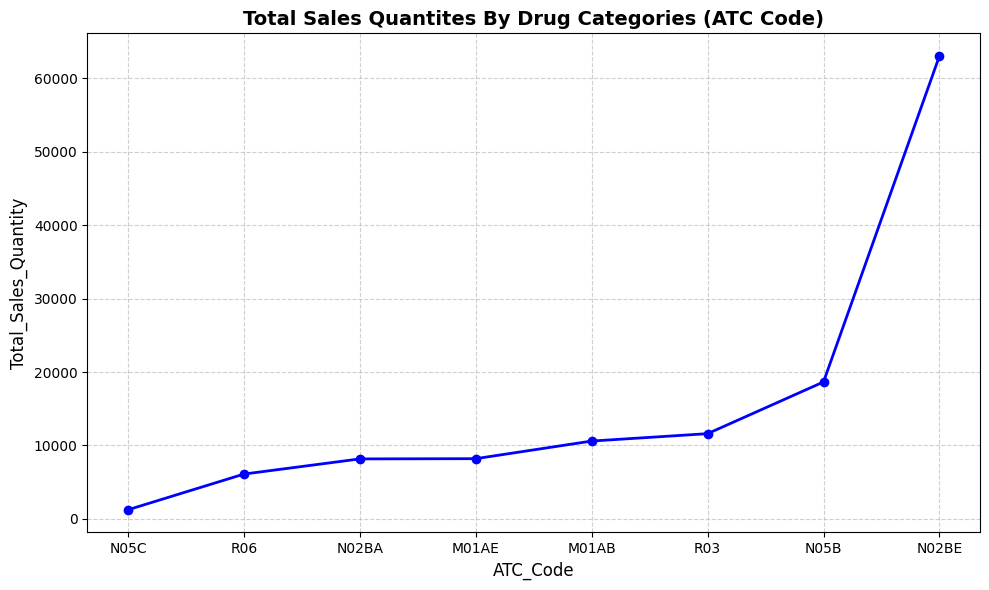

In [ ]:
from matplotlib import colors
from matplotlib.lines import lineStyles
# What are the total sales quantities for each drug category (ATC code)?

atc_cols = ['M01AB','M01AE','N02BA','N02BE','N05B','N05C','R03','R06']

totals = df[atc_cols].sum().reset_index()
totals.columns = ['ATC_Code','Total_Sales_Quantity']
totals['Total_Sales_Quantity'] = totals['Total_Sales_Quantity'].round(2)
totals = totals.sort_values(by='Total_Sales_Quantity')

print('Total Sales Quantites By Drug Categories (ATC Code)')
print(totals.to_string(index=False))

plt.figure(figsize=(10,6))
plt.plot(totals['ATC_Code'], totals['Total_Sales_Quantity'], marker='o', linestyle='-', color='b', linewidth=2)
plt.title('Total Sales Quantites By Drug Categories (ATC Code)',fontsize=14 ,fontweight='bold')
plt.xlabel('ATC_Code',fontsize=12)
plt.ylabel('Total_Sales_Quantity',fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

In [ ]:
# Which individual drug brands have the highest total sales?

brand_cols = ['M01AB','M01AE','N02BA','N02BE','N05B','N05C','R03','R06']

brand_totals = df[brand_cols].sum().reset_index()
brand_totals.columns = ['Brands','Total_Sales_Quantity']
brand_totals['Total_Sales_Quantity'] = brand_totals['Total_Sales_Quantity'].round(2)
brand_totals = brand_totals.sort_values(by='Total_Sales_Quantity',ascending=False)

print('Highest Total Sales By Individual Drug Brands')
print(brand_totals.to_string(index=False))

Highest Total Sales By Individual Drug Brands
Brands  Total_Sales_Quantity
 N02BE              63005.40
  N05B              18645.74
   R03              11608.82
 M01AB              10600.94
 M01AE               8204.62
 N02BA               8172.21
   R06               6107.82
  N05C               1249.96


In [ ]:
# Which three drugs have the highest sales in January 2015, July 2016, September 2017.

atc_cols = ['M01AB','M01AE','N02BA','N02BE','N05B','N05C','R03','R06']

target_periods = [(2015,1,'January 2015'),
                  (2016,7,'July 2016'),
                  (2017,9,'September 2017')]

for Year, Month, Label in target_periods:
  target_df = df[(df['Year'] == Year) & (df['Month'] == Month)]

  category_sum = target_df[atc_cols].sum().reset_index()
  category_sum.columns = ['Drug', 'Sales']

  top_3 = category_sum.sort_values(by='Sales', ascending=False).head(3)

  print(f"Top 3 Drugs With Highest Sales In {Label}")
  for row in top_3.itertuples():
    print(f'{row.Drug}: {row.Sales:.2f}')
  print()

Top 3 Drugs With Highest Sales In January 2015
N02BE: 1044.24
N05B: 463.00
R03: 177.25

Top 3 Drugs With Highest Sales In July 2016
N02BE: 652.36
N05B: 240.00
M01AB: 194.53

Top 3 Drugs With Highest Sales In September 2017
N02BE: 863.75
N05B: 223.00
R03: 139.00



In [ ]:
# Which drug has sold the most often in 2017?

df_2017 = df[df['Year'] == 2017]

atc_cols = ['M01AB','M01AE','N02BA','N02BE','N05B','N05C','R03','R06']

total_qty = df_2017[atc_cols].sum().reset_index()
total_qty.columns = ['ATC_Code', 'Total_Quantity_2017']
total_qty['Total_Quantity_2017'] = total_qty['Total_Quantity_2017'].round(2)
total_qty = total_qty.sort_values(by='Total_Quantity_2017', ascending=False)

frequency = (df_2017[atc_cols]>0).sum().reset_index()
frequency.columns = ['ATC_Code','Days Sold']

summary_2017 = pd.merge(total_qty,frequency, on='ATC_Code')
print('2017 Drugs Sales Performance Summary')
print(summary_2017.to_string(index=False))

plt.figure(figsize=(10, 8))
plt.pie(
    summary_2017['Total_Quantity_2017'],
    labels=summary_2017['ATC_Code'],
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.Paired.colors
)
plt.title('2017 Sales Quantity Share by Drug Category (ATC Code)', fontsize=14, fontweight='bold')
plt.tight_layout()

plt.show()


2017 Drugs Sales Performance Summary
ATC_Code  Total_Quantity_2017  Days Sold
   N02BE              9258.80        361
    N05B              2555.54        356
     R03              1893.61        286
   M01AB              1846.62        360
   M01AE              1387.30        360
   N02BA              1288.30        350
     R06               988.86        329
    N05C               180.33         99


In [ ]:
# Which drug category has the highest average daily sales?

atc_cols = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

avg_sales = df[atc_cols].mean().reset_index()
avg_sales.columns = ['ATC_Codes','Average_Daily_Sales(Units)']
avg_sales['Average_Daily_Sales(Units)']= avg_sales['Average_Daily_Sales(Units)'].round(2)
avg_sales= avg_sales.sort_values(by='Average_Daily_Sales(Units)',ascending=False)

print('Highest Average Daily Sales By Drug Category')
print(avg_sales.to_string(index=False))

Highest Average Daily Sales By Drug Category
ATC_Codes  Average_Daily_Sales(Units)
    N02BE                       29.92
     N05B                        8.85
      R03                        5.51
    M01AB                        5.03
    M01AE                        3.90
    N02BA                        3.88
      R06                        2.90
     N05C                        0.59


Average R03 Sales By Month
 Month  Avg_R03_Sales
    12           7.92
    10           7.21
     2           6.90
     1           6.84
     3           6.29
    11           6.23
     4           5.77
     5           5.01
     9           4.40
     6           4.35
     8           3.10
     7           2.96


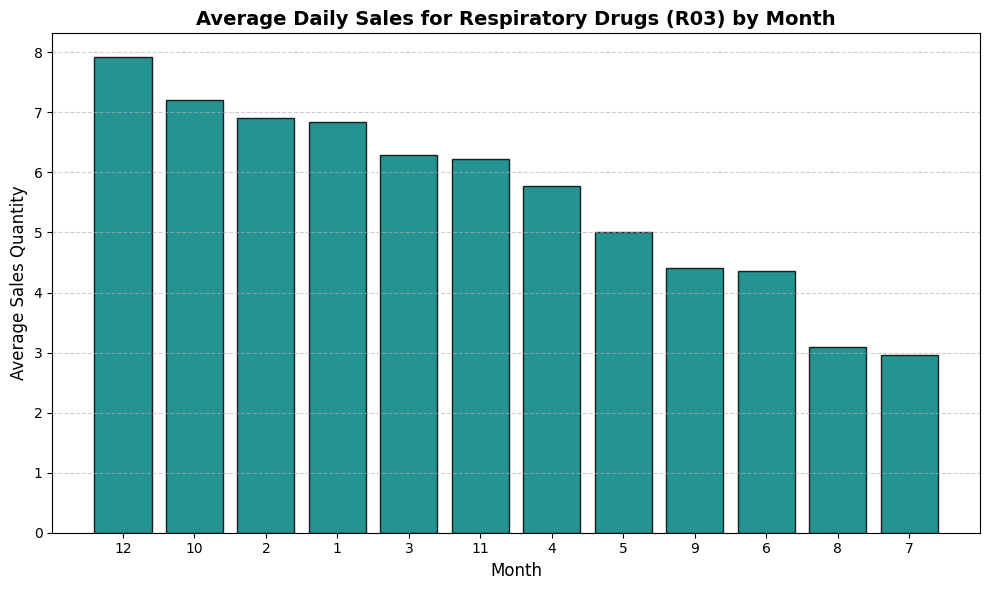

In [ ]:
# Are respiratory drugs (R03) sold more during specific months?

monthly_r03 = df.groupby('Month')['R03'].mean().reset_index()
monthly_r03.columns = ['Month', 'Avg_R03_Sales']

monthly_r03['Avg_R03_Sales'] = monthly_r03['Avg_R03_Sales'].round(2)

monthly_r03 = monthly_r03.sort_values(by='Avg_R03_Sales',ascending=False)

print('Average R03 Sales By Month')
print(monthly_r03.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.bar(monthly_r03['Month'].astype(str), monthly_r03['Avg_R03_Sales'], color='teal', edgecolor='black', alpha=0.85)
plt.title('Average Daily Sales for Respiratory Drugs (R03) by Month', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Sales Quantity', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()